In [2]:
from google.colab import files
uploaded = files.upload()

Saving projeto_final_vitaldb.zip to projeto_final_vitaldb.zip


In [3]:
!unzip -q projeto_final_vitaldb.zip
%cd projeto_final_vitaldb
!ls
!python --version

/content/projeto_final_vitaldb
config.json  README.md	replay_embeddings.py  run_pipeline.py  summarize.py
evidence     reference	requirements.txt      source
Python 3.13.18


In [4]:
!pip install -q uv
!uv python install 3.12
!uv venv --python 3.12 .venv
!.venv/bin/python --version

Installed Python 3.12.16 in 1.90s
 + cpython-3.12.16-linux-x86_64-gnu (python3.12)
Using CPython 3.12.16
Creating virtual environment at: .venv
Activate with: source .venv/bin/activate
Python 3.12.16


In [5]:
!uv pip install --python .venv/bin/python -r requirements.txt

Resolved 42 packages in 579ms
Prepared 42 packages in 7.61s
Installed 42 packages in 351ms
 + certifi==2026.11.20
 + charset-normalizer==3.5.3
 + coloredlogs==15.0.1
 + contourpy==1.3.3
 + cycler==0.12.1
 + duckdb==1.1.3
 + filelock==4.3.1
 + flatbuffers==25.12.19
 + fonttools==4.69.1
 + fsspec==2026.9.0
 + huggingface-hub==0.26.2
 + humanfriendly==10.0
 + idna==3.20
 + joblib==1.4.2
 + kiwisolver==1.5.1
 + matplotlib==3.9.2
 + mpmath==1.3.0
 + numpy==1.26.4
 + onnxruntime==1.18.1
 + packaging==26.4
 + pandas==2.2.3
 + pillow==13.0.0
 + protobuf==7.36.2
 + pyarrow==20.0.0
 + pyparsing==3.3.3
 + python-dateutil==4.0.0
 + pytz==2026.6
 + pyyaml==6.0.4
 + regex==2026.11.25
 + requests==2.32.4
 + safetensors==0.8.0
 + scikit-learn==1.5.2
 + scipy==1.14.1
 + sympy==1.14.0
 + tabulate==0.9.0
 + threadpoolctl==3.8.0
 + tokenizers==0.20.3
 + tqdm==4.70.1
 + transformers==4.46.3
 + typing-extensions==4.16.0
 + tzdata==2026.6
 + urllib3==2.8.0


In [6]:
!.venv/bin/python run_pipeline.py

2026-11-26T13:40:09.839947+00:00 INICIO ambiente
2026-11-26T13:40:09.843982+00:00 SUCCESS ambiente
2026-11-26T13:40:09.844630+00:00 INICIO ingestao_etl
2026-11-26T13:40:12.536186+00:00 SUCCESS ingestao_etl
2026-11-26T13:40:12.537290+00:00 INICIO qualidade
2026-11-26T13:40:13.495596+00:00 Concluido: 30 validos; 0 em quarentena.
2026-11-26T13:40:13.495804+00:00 Relatorio: /content/projeto_final_vitaldb/runs/20261126T134009806984Z/aula03_qualidade_sql/outputs/quality_results.md
2026-11-26T13:40:13.661871+00:00 SUCCESS qualidade
2026-11-26T13:40:13.662803+00:00 INICIO regressao
2026-11-26T13:40:46.834447+00:00 Concluido: 30 predicoes fora do paciente; 7 pacientes.
2026-11-26T13:40:46.834667+00:00 MAE: 11.18 mmHg | RMSE: 17.19 mmHg
2026-11-26T13:40:46.834767+00:00 Relatorio: /content/projeto_final_vitaldb/runs/20261126T134009806984Z/aula04_machine_learning/outputs/evaluation_report.md
2026-11-26T13:40:47.034985+00:00 SUCCESS regressao
2026-11-26T13:40:47.036427+00:00 INICIO embeddings
2026-

In [8]:
from pathlib import Path
import json

ultima_execucao = sorted(Path("runs").glob("*"))[-1]
manifesto = json.loads((ultima_execucao / "run_manifest.json").read_text())

print("Status geral:", manifesto["status"])

for etapa in manifesto["steps"]:
    print(etapa["name"], "-", etapa["status"], "-", etapa["seconds"], "segundos")

Status geral: success
ambiente - success - 0.004 segundos
ingestao_etl - success - 2.692 segundos
qualidade - success - 1.125 segundos
regressao - success - 33.372 segundos
embeddings - success - 7.989 segundos
relatorio - success - 1.931 segundos


cosine_similarity_matrix.png


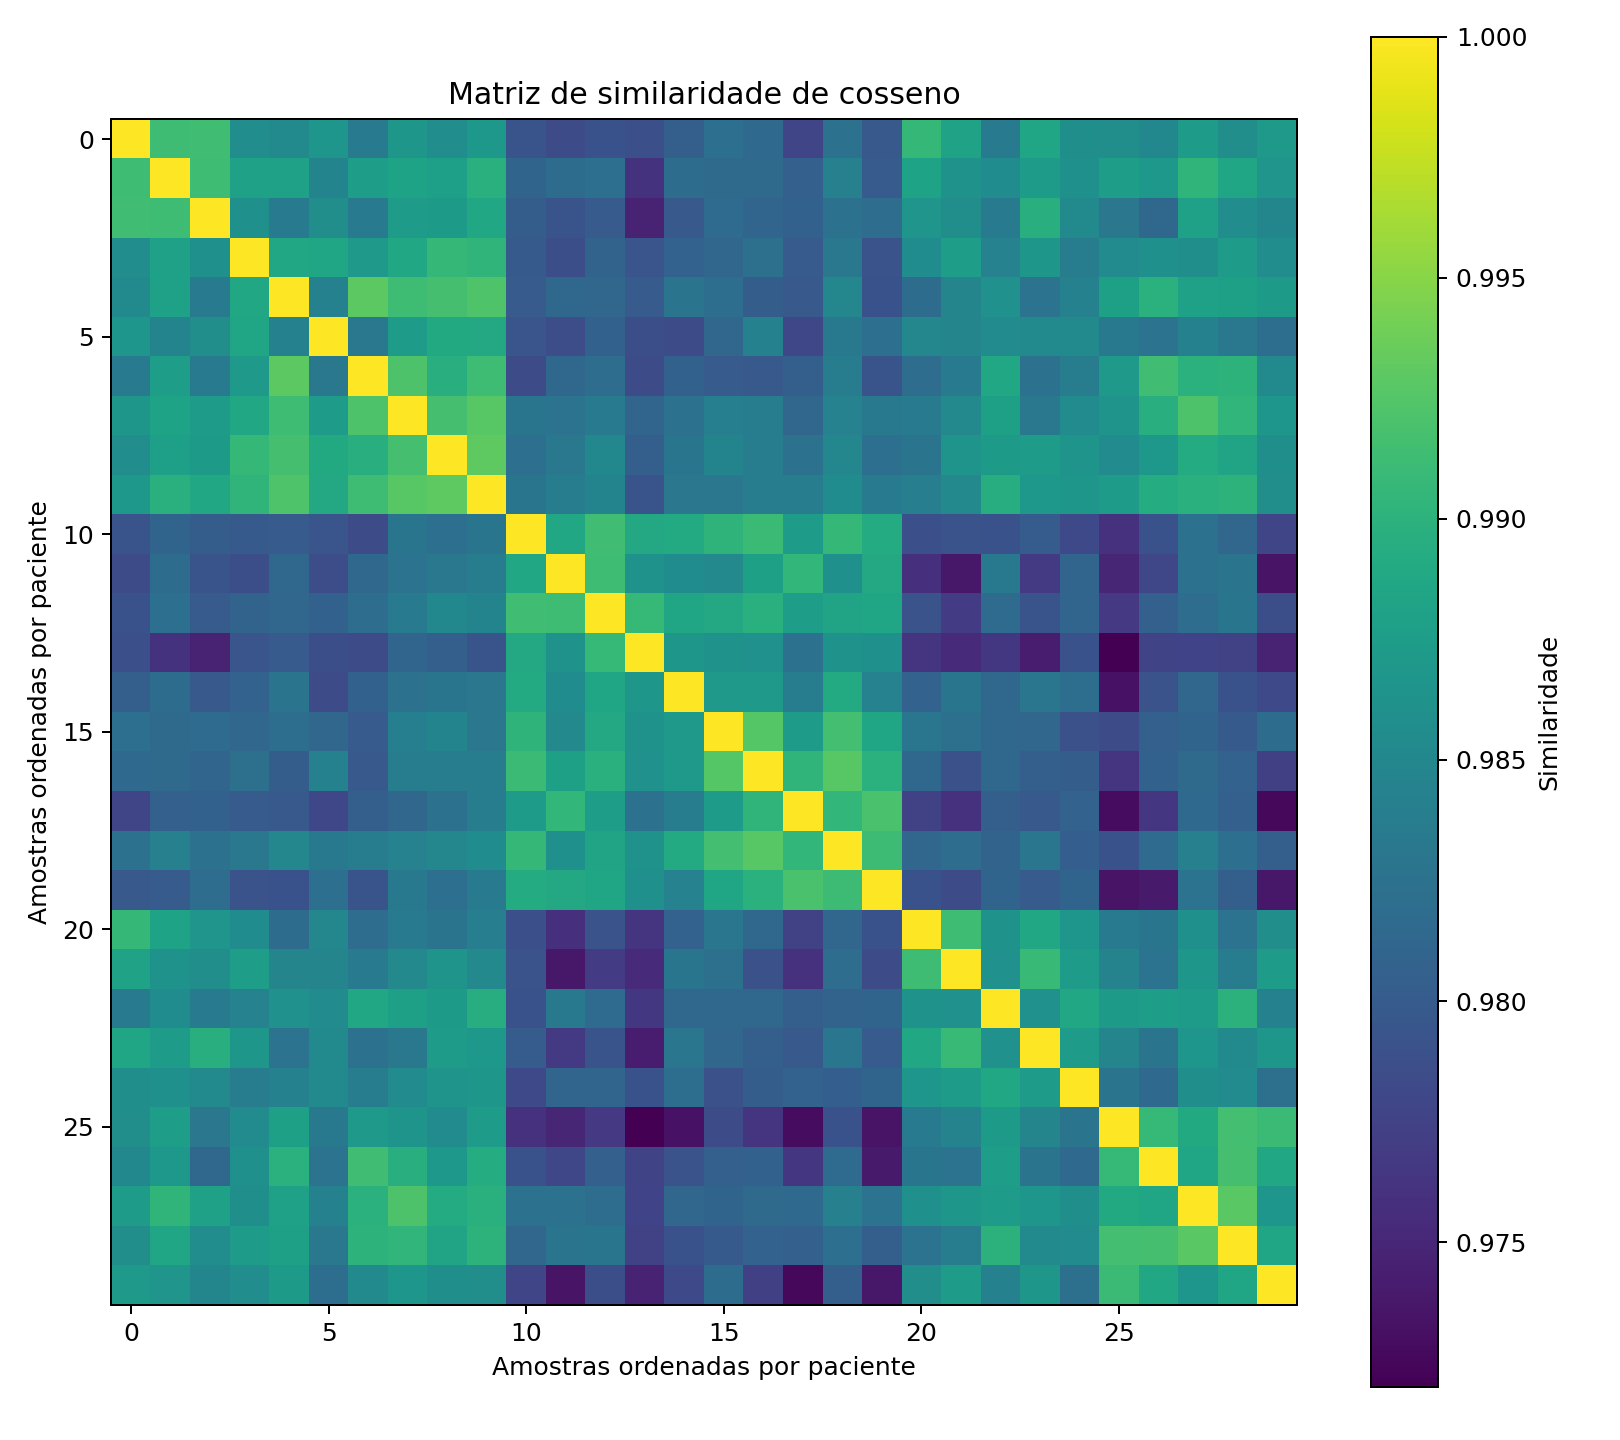

embedding_pca_by_patient.png


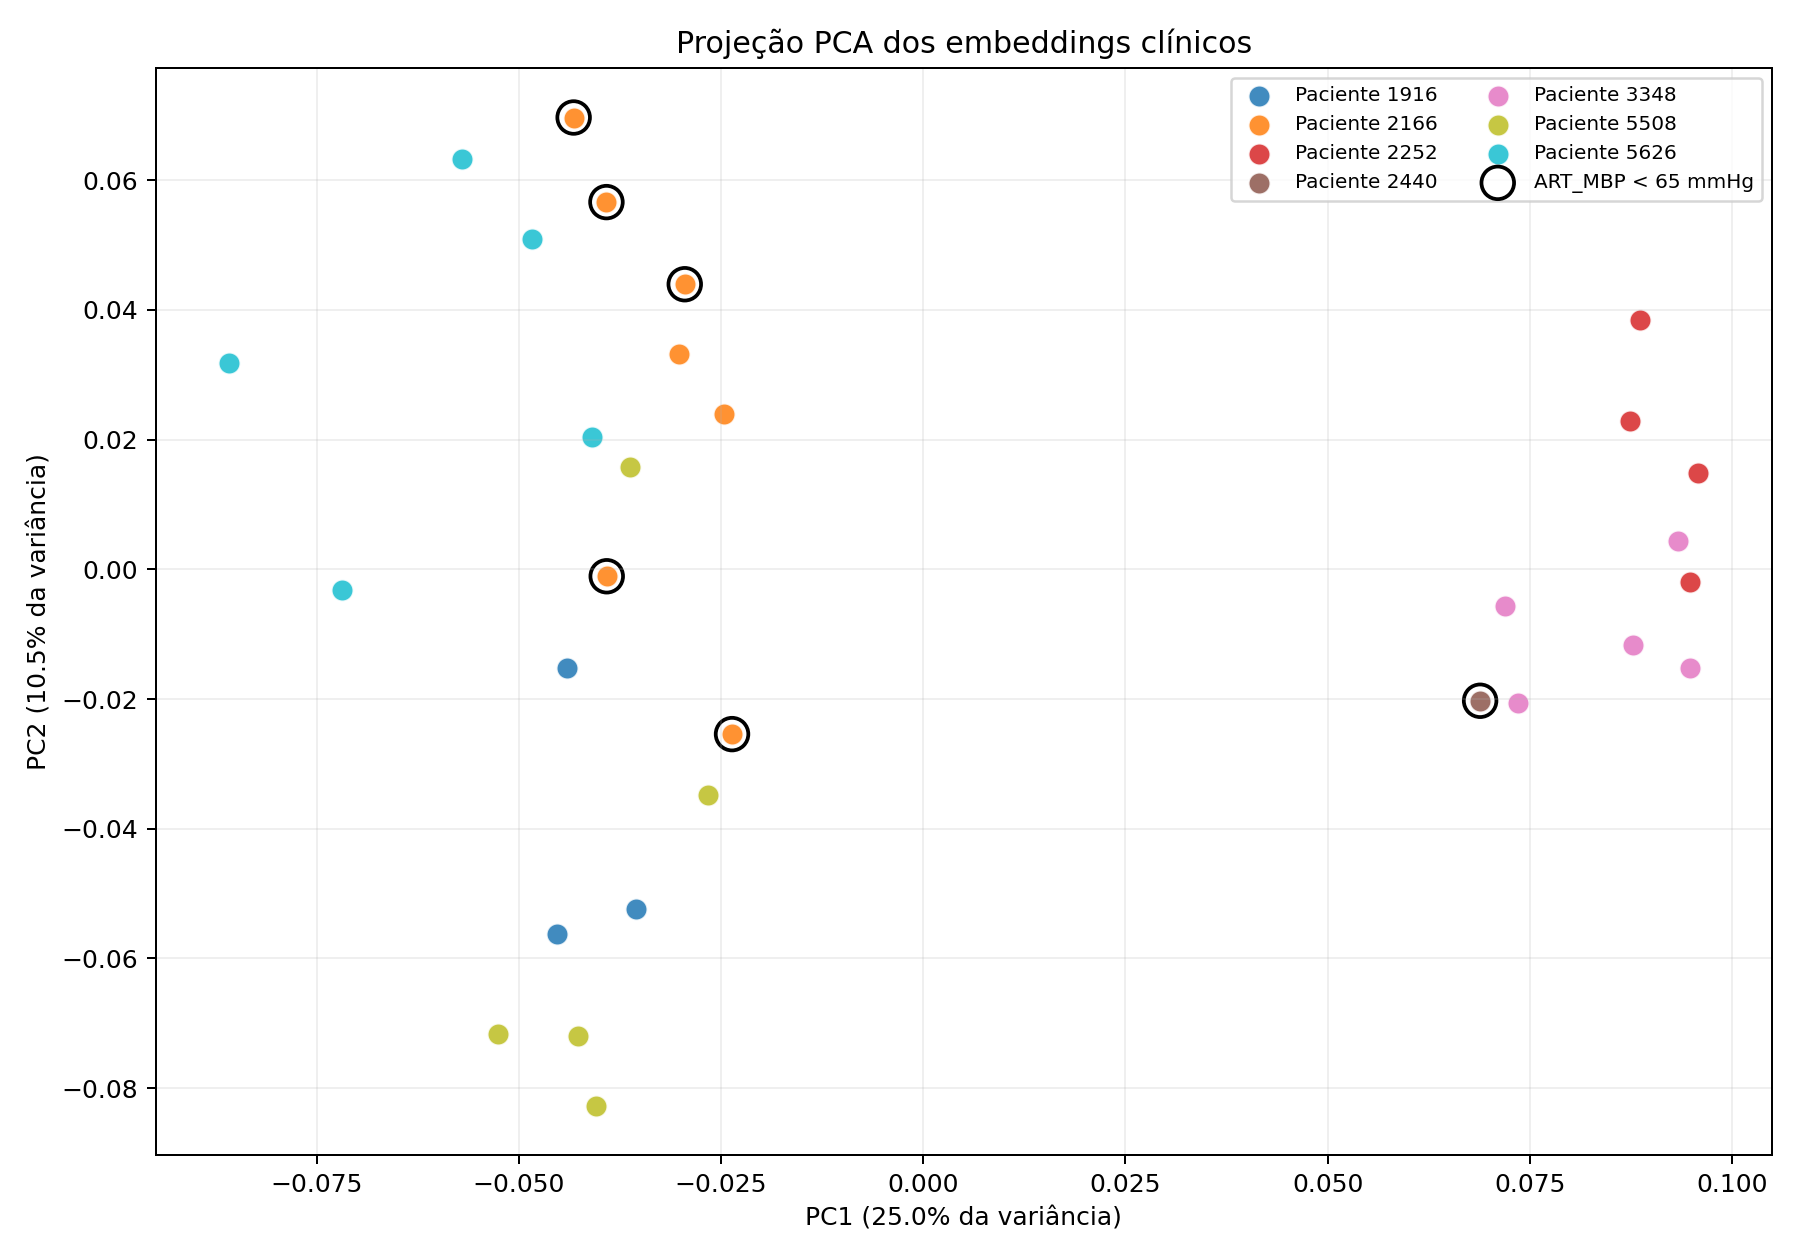

bland_altman.png


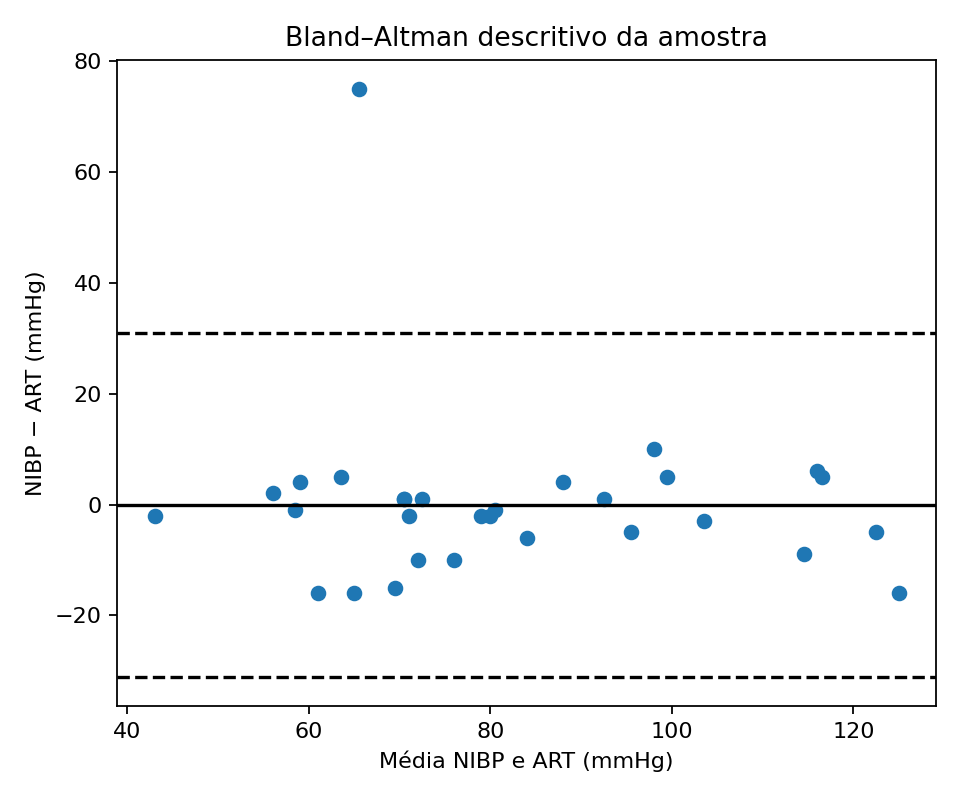

predicoes.png


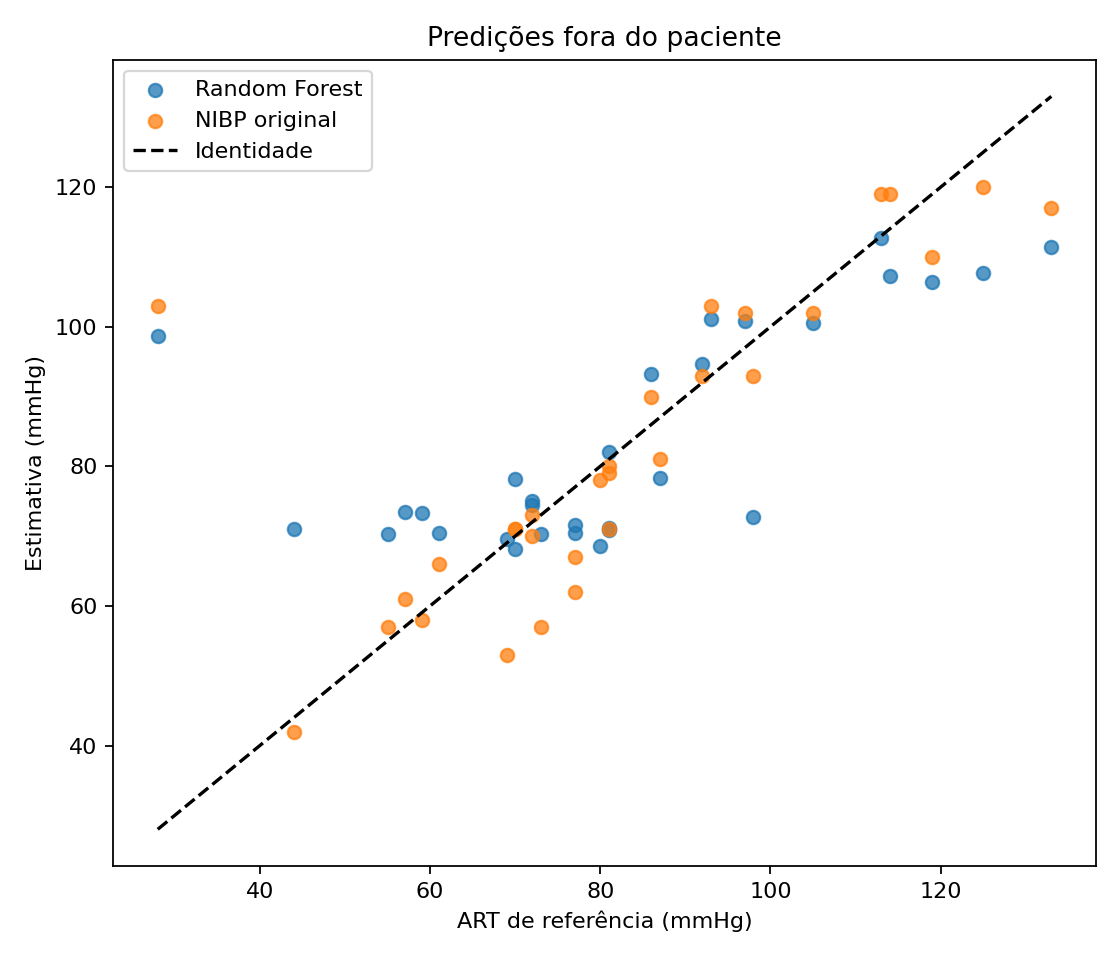

In [9]:
from IPython.display import Image, display

for figura in sorted(ultima_execucao.rglob("*.png")):
    print(figura.name)
    display(Image(filename=str(figura)))

In [10]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/evidencias_colab",
    "zip",
    root_dir=ultima_execucao
)

files.download("/content/evidencias_colab.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

with ZipFile("/content/evidencias_colab_final.zip", "w", ZIP_DEFLATED) as z:
    for arquivo in ultima_execucao.rglob("*"):
        if arquivo.is_file():
            caminho = arquivo.relative_to(ultima_execucao)
            if not any(p in (".cache", "__pycache__", ".venv") for p in caminho.parts):
                z.write(arquivo, caminho)

files.download("/content/evidencias_colab_final.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>